<a href="https://colab.research.google.com/github/MonishDY/AI-Track/blob/main/Module%204%20-%20Deep%20Learning/Assignment%202/Neural_Network_Practice_10_Questions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

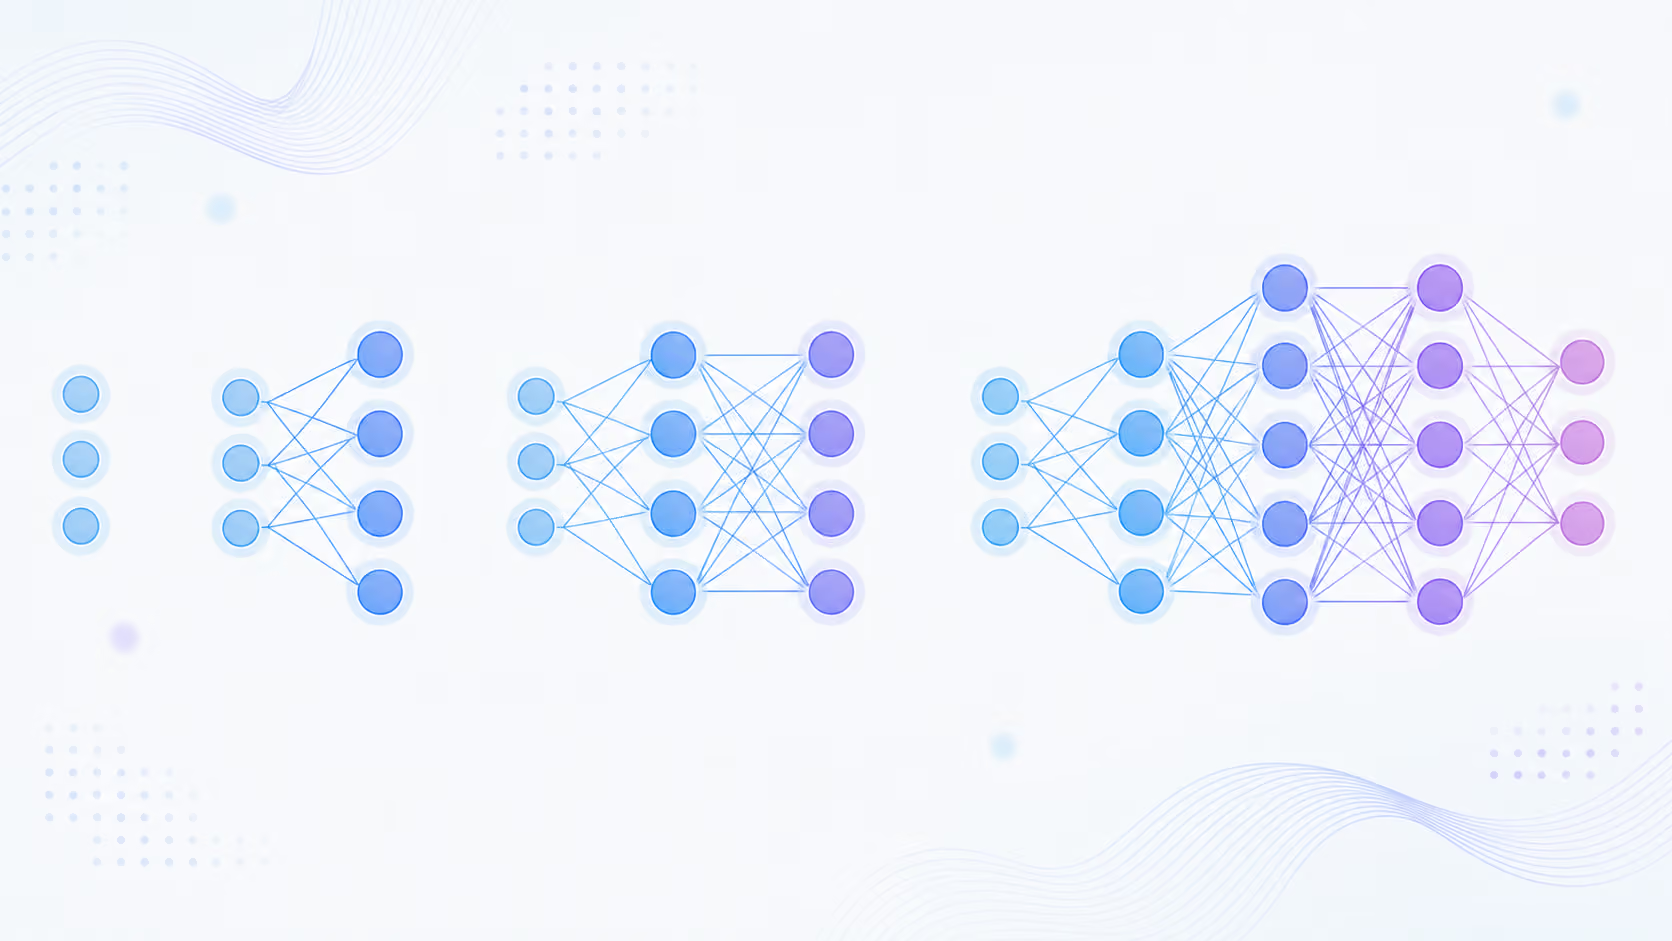

# Neural Network Practice – 10 Questions (PyTorch)

**Level:** Beginner to Intermediate  
**Focus:** Feed-forward neural networks, loss functions, optimization algorithms, validation, and early stopping.

## Problem statement
Build a neural network that predicts whether a breast-cancer tumour is **malignant (1)** or **benign (0)** using measurements from the Wisconsin Breast Cancer dataset.

### Learning outcomes
By completing the 10 questions, you will:
- prepare tabular data for a neural network;
- create a PyTorch model and understand its forward pass;
- train with different optimizers;
- monitor training and validation loss;
- implement **early stopping** to reduce overfitting.

### Instructions
1. Complete the questions in order.
2. Run each cell and inspect the output before moving on.
3. Use the validation set for model selection. Keep the test set for the final evaluation.
4. The notebook contains starter code and `TODO` markers; fill them in.
5. Suggested packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `torch`.

> Dataset note: the dataset is loaded directly from scikit-learn, so no separate CSV download is required.

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.1+cpu
Device: cpu


## Question 1 – Load and inspect the dataset

Load the breast-cancer dataset, create a pandas DataFrame, and inspect its shape, first five rows, target names, and class distribution.

**Tasks**
- Load features into `X` and labels into `y`.
- Print the number of rows and features.
- Display the class counts.

In [2]:
# Load the Breast Cancer dataset
data = load_breast_cancer(as_frame=True)

# Features and binary labels. scikit-learn encodes malignant=0, benign=1;
# invert the labels so this notebook uses malignant=1 and benign=0.
X = data.data.copy()
y = 1 - data.target

print(f"Rows: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print("\nFirst five rows:")
display(X.head())

Rows: 569
Features: 30

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("\nTarget names in the original scikit-learn dataset:", data.target_names)
print("Notebook label mapping: 0 = benign, 1 = malignant")
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(index={0: "Benign (0)", 1: "Malignant (1)"}))


Target names in the original scikit-learn dataset: ['malignant' 'benign']
Notebook label mapping: 0 = benign, 1 = malignant

Class distribution:
target
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64


## Question 2 – Split the data correctly

Split the data into **training (70%)**, **validation (15%)**, and **test (15%)** sets.

**Tasks**
- Use `train_test_split` twice.
- Use `stratify` so class proportions remain similar.
- Use `random_state=SEED`.
- Print the shape of all three splits.

In [4]:
# First split: 70% training and 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Second split: divide the temporary 30% equally into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (398, 30) (398,)
Validation: (85, 30) (85,)
Test: (86, 30) (86,)


## Question 3 – Scale the features

Neural networks generally train more reliably when numerical features are on comparable scales.

**Tasks**
- Fit `StandardScaler` on the training features only.
- Transform training, validation, and test features using that same scaler.
- Convert the arrays to `float32` PyTorch tensors.
- Convert labels to `float32` tensors and reshape them to `(n, 1)`.

**Important:** Never fit the scaler on validation or test data.

In [5]:
# Fit the scaler only on the training data to prevent data leakage
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

In [6]:
# Convert features and labels to float32 tensors; labels must have shape (n, 1)
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32).view(-1, 1)

print("Feature tensor shapes:", X_train_t.shape, X_val_t.shape, X_test_t.shape)
print("Label tensor shapes:", y_train_t.shape, y_val_t.shape, y_test_t.shape)

Feature tensor shapes: torch.Size([398, 30]) torch.Size([85, 30]) torch.Size([86, 30])
Label tensor shapes: torch.Size([398, 1]) torch.Size([85, 1]) torch.Size([86, 1])


## Question 4 – Create DataLoaders

Create a `TensorDataset` and `DataLoader` for each split.

**Tasks**
- Use a batch size of 32.
- Shuffle only the training DataLoader.
- Keep validation and test DataLoaders unshuffled.
- Print the number of batches in each loader.

**Think:** Why is shuffling useful during training, but unnecessary for evaluation?

In [7]:
BATCH_SIZE = 32

# Build TensorDataset objects
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# Shuffle training batches only; evaluation order does not affect metrics
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 13
Validation batches: 3
Test batches: 3


## Question 5 – Build the neural network

Create a feed-forward neural network for binary classification.

**Required architecture**
- Input layer: number of dataset features
- Hidden layer 1: 32 neurons + ReLU
- Hidden layer 2: 16 neurons + ReLU
- Output layer: 1 neuron (raw logit; no sigmoid in the model)

**Tasks**
- Define a class named `CancerNN` using `nn.Module`.
- Implement `__init__()` and `forward()`.
- Create the model and move it to `device`.
- Print the model architecture.

In [8]:
# Define the feed-forward neural network
class CancerNN(nn.Module):
    def __init__(self, input_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # One raw logit for binary classification
        )

    def forward(self, x):
        return self.network(x)

In [10]:
# Create the model and move it to the selected device
model = CancerNN(input_features=X_train_t.shape[1]).to(device)
model

CancerNN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)

## Question 6 – Choose the loss function and inspect predictions

Configure the binary-classification loss and inspect one forward pass.

**Tasks**
- Use `nn.BCEWithLogitsLoss()`.
- Pass one batch through the model.
- Print the input shape, output shape, and loss.
- Explain why the output layer has one neuron and why sigmoid is not added before this loss.

In [11]:
criterion = nn.BCEWithLogitsLoss()

# Get one batch and move it to the selected device
batch_features, batch_labels = next(iter(train_loader))
batch_features = batch_features.to(device)
batch_labels = batch_labels.to(device)

In [12]:
# Run a forward pass and calculate the loss
model.eval()
with torch.no_grad():
    batch_logits = model(batch_features)
    batch_loss = criterion(batch_logits, batch_labels)

print("Input shape:", batch_features.shape)
print("Output shape:", batch_logits.shape)
print("Loss:", batch_loss.item())

Input shape: torch.Size([32, 30])
Output shape: torch.Size([32, 1])
Loss: 0.7135574817657471


*The output layer has one neuron because the task is binary classification: it produces one logit per sample. BCEWithLogitsLoss combines the sigmoid operation and binary cross-entropy in a numerically stable calculation, so a separate sigmoid should not be applied before the loss.*

## Question 7 – Train with SGD

Train the model using **Stochastic Gradient Descent (SGD)**.

**Tasks**
- Use `torch.optim.SGD` with learning rate `0.01`.
- Train for up to 100 epochs.
- In each batch: clear gradients, forward pass, calculate loss, backpropagate, and update weights.
- Record and plot average training loss per epoch.

In [13]:
# Create a fresh model and SGD optimizer
model_sgd = CancerNN(input_features=X_train_t.shape[1]).to(device)
optimizer_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
criterion = nn.BCEWithLogitsLoss()

In [14]:
# SGD Training
sgd_train_losses = []
epochs_sgd = 100

for epoch in range(epochs_sgd):
    model_sgd.train()
    running_loss = 0.0

    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)

        optimizer_sgd.zero_grad()
        logits = model_sgd(features)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer_sgd.step()

        running_loss += loss.item() * features.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    sgd_train_losses.append(epoch_loss)

print(f"Final SGD training loss: {sgd_train_losses[-1]:.4f}")

Final SGD training loss: 0.0769


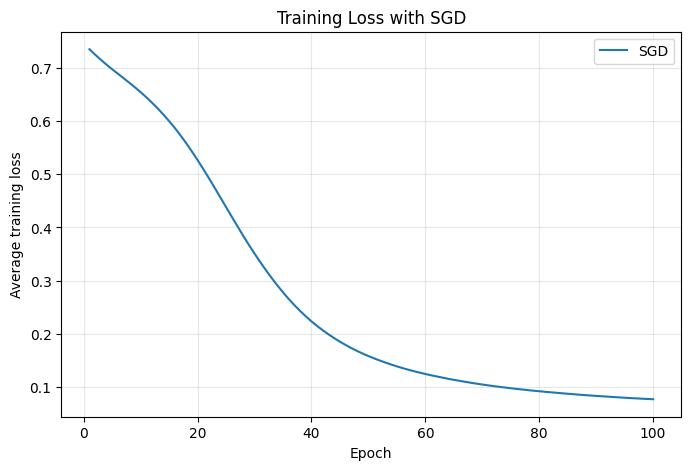

In [15]:
# Visualize the training loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs_sgd + 1), sgd_train_losses, label="SGD")
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Training Loss with SGD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Question 8 – Compare optimization algorithms

Compare **SGD**, **SGD with momentum**, and **Adam** under the same training setup.

**Tasks**
- Train a fresh model for each optimizer.
- Suggested settings: SGD (`lr=0.01`), SGD with momentum (`lr=0.01`, `momentum=0.9`), Adam (`lr=0.001`).
- Record training loss for each epoch.
- Plot all three loss curves on one graph.
- State which optimizer converged fastest in your experiment.

**Important:** Use the same architecture, data split, batch size, and epoch count for a fair comparison.

In [16]:
def train_for_comparison(model, optimizer, train_loader, epochs=100):
    losses = []
    model.train()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)

            optimizer.zero_grad()
            logits = model(features)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * features.size(0)

        losses.append(running_loss / len(train_loader.dataset))

    return losses

In [17]:
# Create three fresh models so each optimizer starts from an independent initialization
comparison_models = {
    "SGD": CancerNN(input_features=X_train_t.shape[1]).to(device),
    "SGD + Momentum": CancerNN(input_features=X_train_t.shape[1]).to(device),
    "Adam": CancerNN(input_features=X_train_t.shape[1]).to(device)
}

comparison_optimizers = {
    "SGD": torch.optim.SGD(comparison_models["SGD"].parameters(), lr=0.01),
    "SGD + Momentum": torch.optim.SGD(
        comparison_models["SGD + Momentum"].parameters(), lr=0.01, momentum=0.9
    ),
    "Adam": torch.optim.Adam(comparison_models["Adam"].parameters(), lr=0.001)
}

comparison_losses = {}
for name in comparison_models:
    comparison_losses[name] = train_for_comparison(
        comparison_models[name], comparison_optimizers[name], train_loader, epochs=100
    )

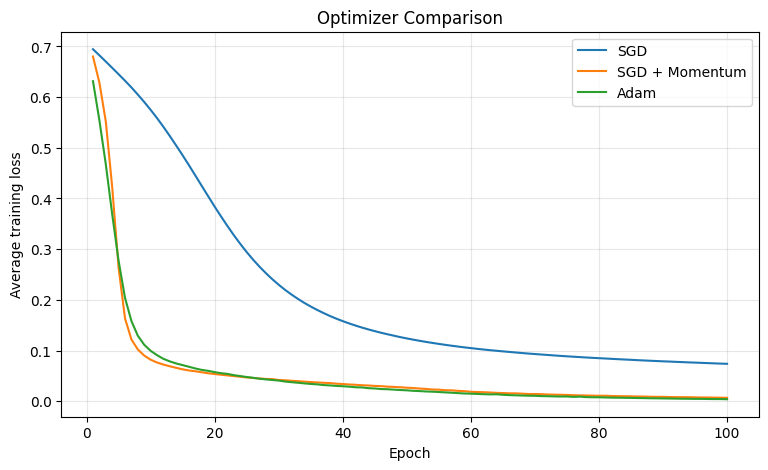

In [18]:
# Compare the models
plt.figure(figsize=(9, 5))
for name, losses in comparison_losses.items():
    plt.plot(range(1, len(losses) + 1), losses, label=name)
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
final_losses = {name: values[-1] for name, values in comparison_losses.items()}
print("Final training losses:", {k: round(v, 4) for k, v in final_losses.items()})
print("Lowest final training loss:", min(final_losses, key=final_losses.get))

Final training losses: {'SGD': 0.0739, 'SGD + Momentum': 0.0068, 'Adam': 0.004}
Lowest final training loss: Adam


## Question 9 – Implement early stopping

Add **early stopping** using validation loss.

Early stopping stops training when validation loss does not improve for a chosen number of consecutive epochs. Restore the model weights from the epoch with the best validation loss.

**Requirements**
- Use Adam with learning rate `0.001`.
- Set `max_epochs = 200` and `patience = 12`.
- Evaluate validation loss at the end of every epoch.
- Save a deep copy of the best model weights.
- Stop when the validation loss has not improved for `patience` epochs.
- Restore the best weights after training.
- Plot training loss and validation loss. Mark the best epoch.

**Think:** Why should early stopping monitor validation loss rather than training loss?

In [20]:
# Create a fresh model, Adam optimizer, and loss function
early_model = CancerNN(input_features=X_train_t.shape[1]).to(device)
early_optimizer = torch.optim.Adam(early_model.parameters(), lr=0.001)
criterion = nn.BCEWithLogitsLoss()

max_epochs = 200
patience = 12
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_weights = None

train_history = []
val_history = []

for epoch in range(max_epochs):
    # Training phase
    early_model.train()
    train_running_loss = 0.0

    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)

        early_optimizer.zero_grad()
        logits = early_model(features)
        loss = criterion(logits, labels)
        loss.backward()
        early_optimizer.step()

        train_running_loss += loss.item() * features.size(0)

    epoch_train_loss = train_running_loss / len(train_loader.dataset)
    train_history.append(epoch_train_loss)

    # Validation phase
    early_model.eval()
    val_running_loss = 0.0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            logits = early_model(features)
            loss = criterion(logits, labels)
            val_running_loss += loss.item() * features.size(0)

    epoch_val_loss = val_running_loss / len(val_loader.dataset)
    val_history.append(epoch_val_loss)

    # Save a deep copy whenever validation loss improves
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(early_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping triggered at epoch {epoch + 1}.")
        break

Early stopping triggered at epoch 34.


Best epoch: 22
Best validation loss: 0.0702
Epochs run: 34


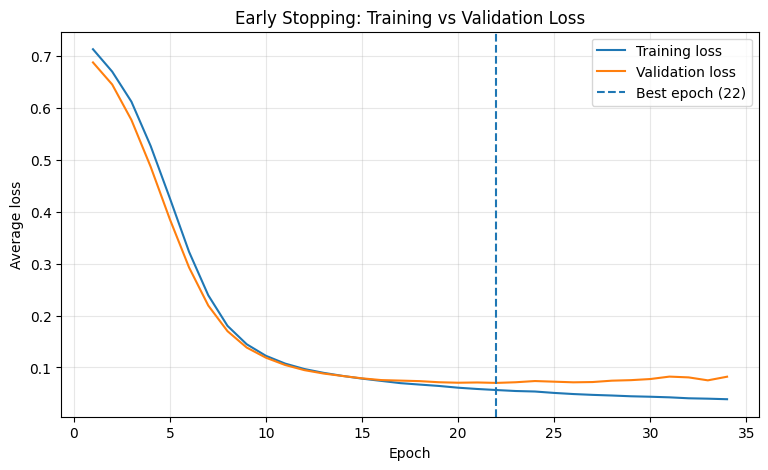

In [21]:
# Restore the weights from the epoch with the lowest validation loss
early_model.load_state_dict(best_weights)
epochs_run = len(train_history)
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Epochs run: {epochs_run}")

plt.figure(figsize=(9, 5))
plt.plot(range(1, epochs_run + 1), train_history, label="Training loss")
plt.plot(range(1, epochs_run + 1), val_history, label="Validation loss")
plt.axvline(best_epoch, linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.title("Early Stopping: Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Question 10 – Final test evaluation and reflection

Evaluate the best early-stopped model on the **test set**, which has not been used for training or model selection.

**Tasks**
- Calculate test loss.
- Convert logits to probabilities using sigmoid.
- Predict class 1 when probability is at least 0.5; otherwise predict class 0.
- Print accuracy, confusion matrix, and classification report.

In [22]:
# Evaluate the restored best model on the held-out test set
early_model.eval()
test_running_loss = 0.0
all_test_logits = []
all_test_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        features, labels = features.to(device), labels.to(device)
        logits = early_model(features)
        loss = criterion(logits, labels)

        test_running_loss += loss.item() * features.size(0)
        all_test_logits.append(logits.cpu())
        all_test_labels.append(labels.cpu())

test_loss = test_running_loss / len(test_loader.dataset)
test_logits = torch.cat(all_test_logits).numpy().ravel()
test_labels = torch.cat(all_test_labels).numpy().astype(int)


In [23]:
# Convert logits to probabilities, then apply the 0.5 decision threshold
test_probabilities = 1 / (1 + np.exp(-test_logits))
test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(test_labels, test_predictions)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(test_labels, test_predictions, labels=[0, 1]))

print("\nClassification report (0 = benign, 1 = malignant):")
print(classification_report(
    test_labels, test_predictions,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

Test loss: 0.0340
Test accuracy: 0.9884

Confusion matrix (rows = actual, columns = predicted):
[[54  0]
 [ 1 31]]

Classification report (0 = benign, 1 = malignant):
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        54
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86



### **Reflection**

**1. What is the difference between an optimizer and a loss function?**

- The loss function measures how far the predictions are from the true labels. The optimizer uses the gradients of that loss to update model parameters and reduce the error.

**2. How does momentum change SGD updates?**

- Momentum uses previous updates to make learning faster and smoother. This can accelerate updates in consistent directions and reduce oscillation.

**3. Why can Adam often converge quickly?**

- Adam adapts the learning rate for each parameter using moving averages of gradients and squared gradients, often making training more efficient with less manual tuning.

**4. What is overfitting, and how can validation loss reveal it?**

- Overfitting happens when a model learns training data too well but performs poorly on new data. Increasing validation loss indicates overfitting.

**5. What are the limitations of using accuracy alone for medical classification?**

- Accuracy can hide class imbalance and does not show the cost of false negatives and false positives. In cancer screening, recall/sensitivity for malignant cases, specificity, precision, F1-score, and the confusion matrix are also important.

## Optional extension challenges

After completing all 10 questions:
- Add dropout to the hidden layers and compare validation loss.
- Try hidden-layer sizes of 64 and 32.
- Change the early-stopping patience to 5 and 20.
- Compare precision, recall, and F1-score, especially for the malignant class.
- Experiment with learning rates and explain how they affect convergence.

## Submission checklist
- [ ] Questions 1–10 completed
- [ ] Training and validation loss plots included
- [ ] Optimizer comparison completed
- [ ] Early stopping implemented and best weights restored
- [ ] Final test metrics reported
- [ ] Reflection questions answered